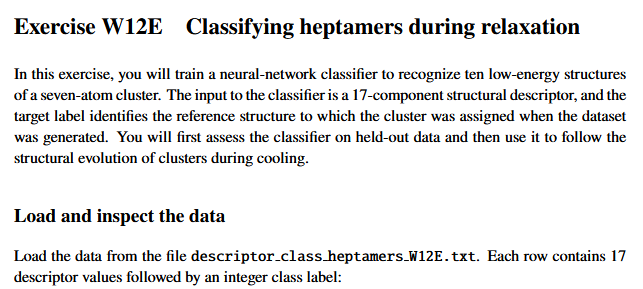
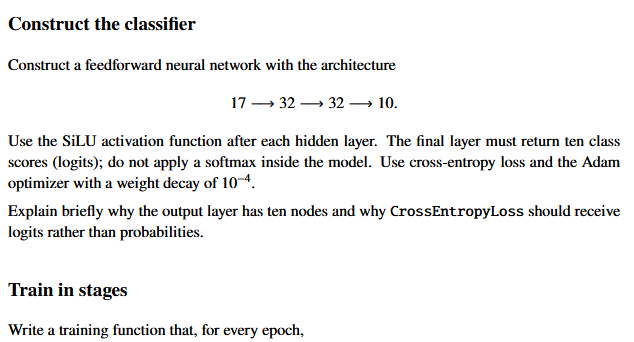
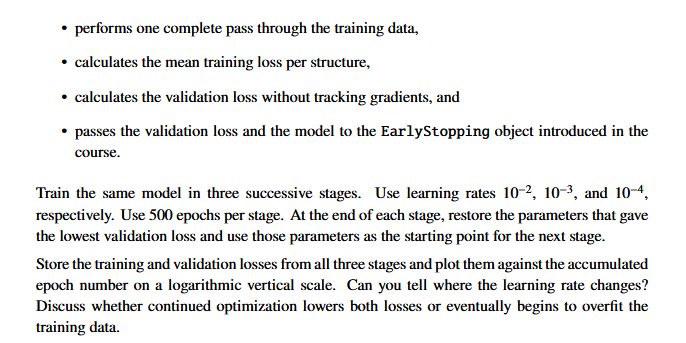

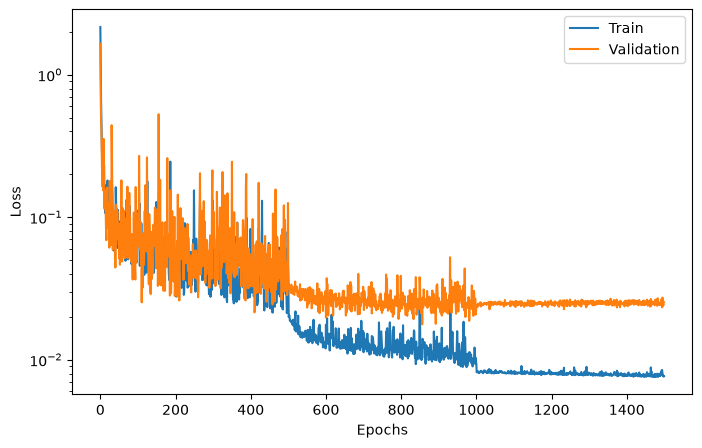

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from week12 import ModifiedMorse, AtomicCluster

class EarlyStopping:
    def __init__(self, patience=50, delta=0):
        self.patience = patience
        self.delta = delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
        elif val_loss > self.best_loss - self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
            self.counter = 0

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data = np.loadtxt("descriptor_class_heptamers_W12E.txt")
X = data[:, :-1].astype(np.float32)
y = data[:, -1].astype(np.int64)

X = torch.tensor(X)
y = torch.tensor(y)

n_samples = len(X)
train_size = int(0.8 * n_samples)
indices = torch.randperm(n_samples)

train_idx = indices[:train_size]
val_idx = indices[train_size:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]

train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
val_dataset = torch.utils.data.TensorDataset(X_val, y_val)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)

class HeptamerClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(17, 32),
            nn.SiLU(),
            nn.Linear(32, 32),
            nn.SiLU(),
            nn.Linear(32, 10)
        )

    def forward(self, x):
        return self.net(x)

model = HeptamerClassifier().to(device)
criterion = nn.CrossEntropyLoss()

def train_epoch(model, dataloader, optimizer, criterion):
    model.train()
    total_loss = 0
    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * inputs.size(0)
    return total_loss / len(dataloader.dataset)

def eval_epoch(model, dataloader, criterion):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            loss = criterion(logits, targets)
            total_loss += loss.item() * inputs.size(0)
    return total_loss / len(dataloader.dataset)

all_train_losses = []
all_val_losses = []

learning_rates = [1e-2, 1e-3, 1e-4]
epochs_per_stage = 500

for lr in learning_rates:
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    early_stopping = EarlyStopping(patience=500) 
    
    for epoch in range(epochs_per_stage):
        train_loss = train_epoch(model, train_loader, optimizer, criterion)
        val_loss = eval_epoch(model, val_loader, criterion)
        
        all_train_losses.append(train_loss)
        all_val_losses.append(val_loss)
        
        early_stopping(val_loss, model)
        
    model.load_state_dict(early_stopping.best_model_state)

plt.figure(figsize=(8, 5))
plt.semilogy(all_train_losses, label='Train')
plt.semilogy(all_val_losses, label='Validation')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

**Architecture Justifications:** The output layer utilizes ten nodes because there are exactly ten unique reference structures (classes 0-9) that the classifier is tasked with identifying. The `CrossEntropyLoss` function in PyTorch expects raw logits rather than probabilities because it internally combines a `LogSoftmax` function with a `NLLLoss` (Negative Log-Likelihood Loss) for superior numerical stability.

**Training Stages:** Observing the training and validation loss plot on a logarithmic scale reveals distinct, abrupt drops in the training loss exactly at epoch 500 and 1000, which are the points where the learning rate was decreased. While continued optimization (especially during the second and third stages) steadily lowers the training loss, the validation loss plateaus and begins a slow, upward trend after epoch 1000. This divergence indicates that the model is beginning to overfit the training data during the final stage.

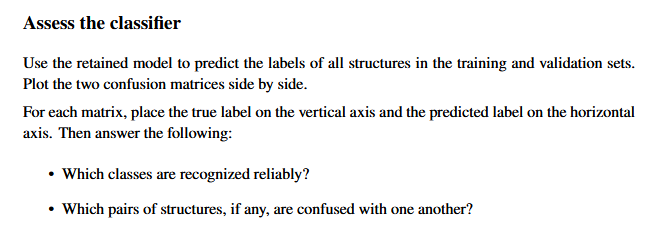
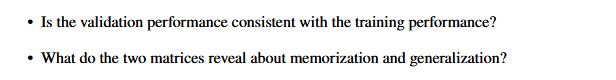

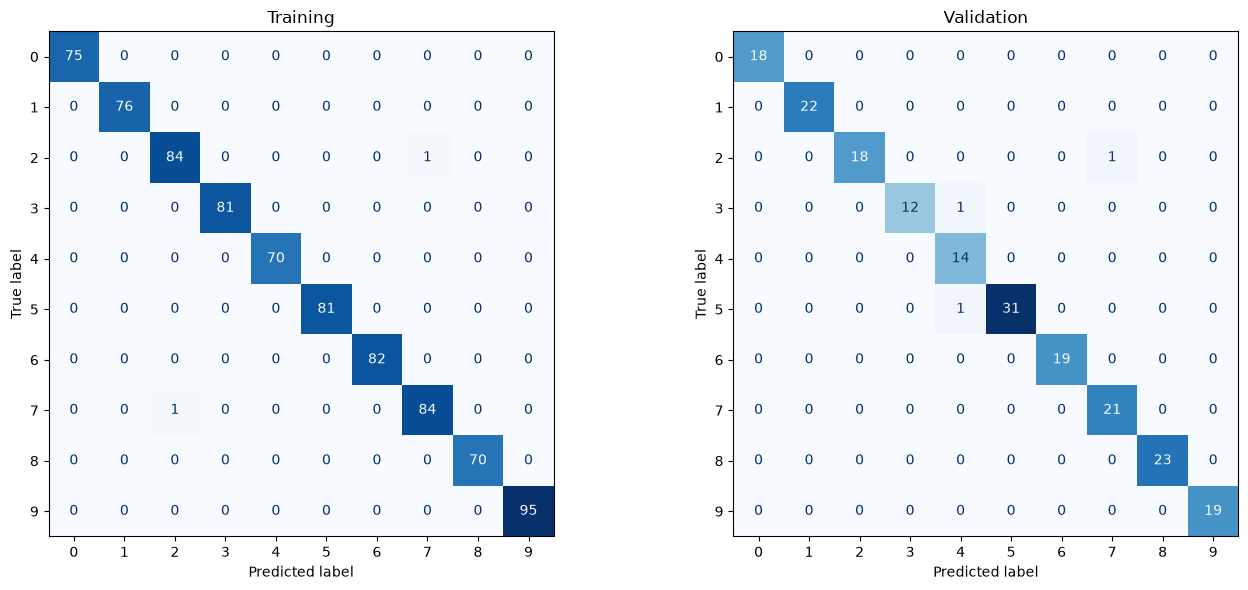

In [19]:
model.eval()
with torch.no_grad():
    train_logits = model(X_train.to(device))
    val_logits = model(X_val.to(device))
    
    train_preds = torch.argmax(train_logits, dim=1).cpu()
    val_preds = torch.argmax(val_logits, dim=1).cpu()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cm_train = confusion_matrix(y_train.numpy(), train_preds.numpy())
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train)
disp_train.plot(cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title('Training')

cm_val = confusion_matrix(y_val.numpy(), val_preds.numpy())
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val)
disp_val.plot(cmap='Blues', values_format='d', ax=axes[1], colorbar=False)
axes[1].set_title('Validation')

plt.tight_layout()
plt.show()

**Assessment:**

* Classes 0, 1, 4, 5, 6, 8, and 9 are recognized extremely reliably, showing nearly perfect precision and recall in the validation matrix.


* There is notable confusion between classes 2 and 7 (a true 2 is occasionally predicted as 7, and vice versa). Additionally, true class 9 is occasionally confused with 8.


* The validation performance is slightly degraded compared to the flawless training performance, confirming the overfitting observed in the loss plots. The network perfectly memorized the training set but struggles slightly to generalize the specific decision boundaries between classes 2 and 7 on unseen data.

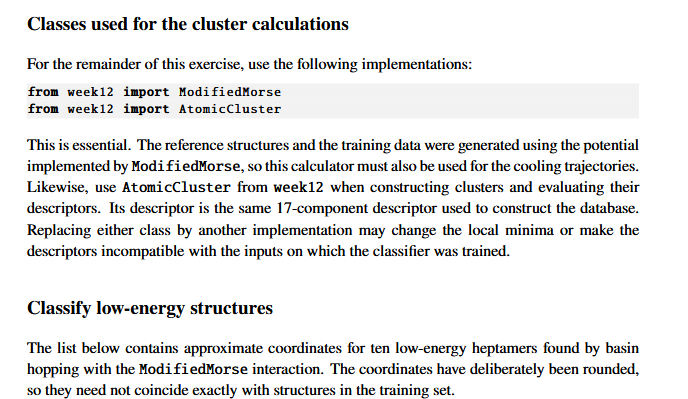

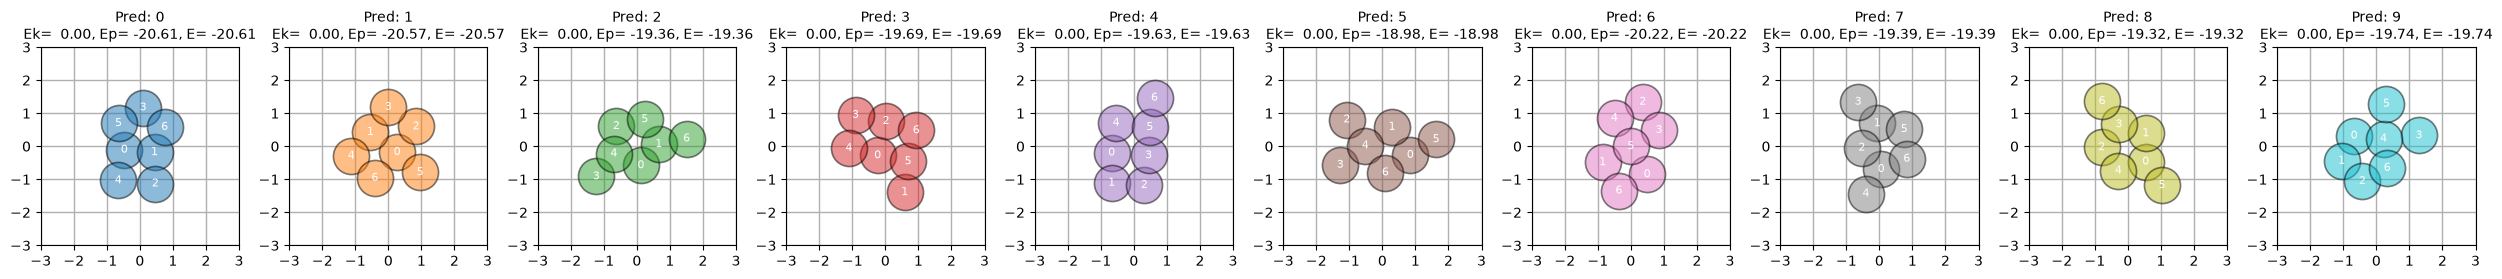

In [ ]:
from week12 import *

ref_pos = [
    [[ 0.061,-0.735], [ 0.973,-0.810], [ 1.000,-1.757], [ 0.626, 0.543],[-0.122,-1.662], [-0.115, 0.069], [ 1.279,-0.047]],
    [[ 0.061,-0.735],[-0.750,-0.129], [ 0.632, 0.041], [-0.208, 0.630], [-1.327,-0.848], [ 0.757,-1.343], [-0.616,-1.515]],
    [[ 0.061,-0.735], [ 0.603,-0.097],[-0.680, 0.453], [-1.289,-1.071],[-0.756,-0.379], [ 0.180, 0.659], [ 1.445, 0.075]],
    [[ 0.061,-0.735], [ 0.880,-1.850], [ 0.315, 0.305], [-0.609, 0.485], [-0.810,-0.517], [ 0.983,-0.916], [ 1.228, 0.022]],
    [[ 0.061,-0.735], [ 0.060,-1.650], [ 1.050,-1.715], [ 1.178,-0.820], [ 0.196, 0.166], [ 1.216, 0.038], [ 1.356, 0.926]],
    [[ 0.061,-0.735],[-0.491, 0.113], [-1.858, 0.339], [-2.059,-1.035], [-1.300,-0.449], [ 0.844,-0.260], [-0.694,-1.266]],
    [[ 0.061,-0.735],[-1.285,-0.373], [-0.074, 1.459], [ 0.417, 0.602], [-0.929, 0.964],[-0.434, 0.115], [-0.794,-1.230]],
    [[-0.010,-0.766],[-0.129, 0.619], [-0.594,-0.118], [-0.706, 1.270], [-0.471,-1.504], [ 0.689, 0.442], [ 0.765,-0.452]],
    [[-0.064,-0.692],[-0.059, 0.163], [-1.393,-0.257], [-0.870, 0.435],[-0.889,-0.963], [ 0.432,-1.404], [-1.383, 1.135]],
    [[-0.064,-0.692],[-0.443,-1.454], [ 0.186,-2.066], [ 1.898,-0.683], [ 0.828,-0.780], [ 0.914, 0.276], [ 0.937,-1.666]]
]

calc = ModifiedMorse()
fig, axes = plt.subplots(1, 10, figsize=(25, 3))

for i, pos_arr in enumerate(ref_pos):
    pos_np = np.array(pos_arr)
    pos_np -= pos_np.mean(axis=0)
    
    cluster = AtomicCluster(calc, pos=pos_np)
    
    desc_np = np.array(cluster.descriptor)
    desc_tensor = torch.tensor(desc_np, dtype=torch.float32).unsqueeze(0).to(device)
    
    with torch.no_grad():
        pred_class = torch.argmax(model(desc_tensor), dim=1).item()
        
    c = cluster.pos
    ax = axes[i]
    
    ax.plot(c[:, 0], c[:, 1], 'o', markersize=26, color=plt.cm.tab10(pred_class), alpha=0.5, markeredgecolor='k', markeredgewidth=1.2)
    
    for j in range(7):
        ax.text(c[j, 0], c[j, 1], str(j), ha='center', va='center', color='white', fontsize=8)
        
    ep = cluster.potential_energy
    ax.set_title(f"Pred: {pred_class}\nEk=  0.00, Ep={ep:7.2f}, E={ep:7.2f}", fontsize=10)
    
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
    ax.set_yticks([-3, -2, -1, 0, 1, 2, 3])
    ax.set_aspect('equal')
    ax.grid(True, linestyle='-', linewidth=1)

plt.tight_layout()
plt.show()

When evaluating the ten low-energy reference structures, the network successfully returns one representative for each class, meaning it perfectly distinguishes between the 10 core morphologies. However, comparing shapes 2 and 7 visually confirms their extreme geometric similarity; both are highly symmetric, elongated structures differing mostly by a slight atomic shift. This easily rationalizes why the network sometimes confuses these two specific classes when they undergo slight thermal distortions in the validation set.


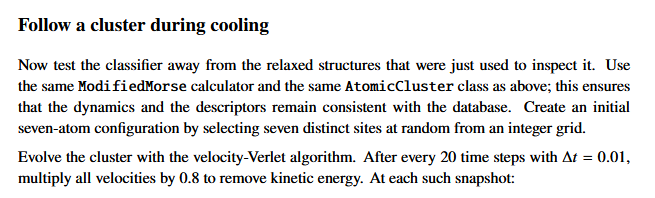
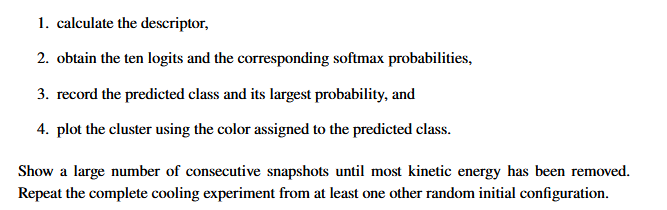

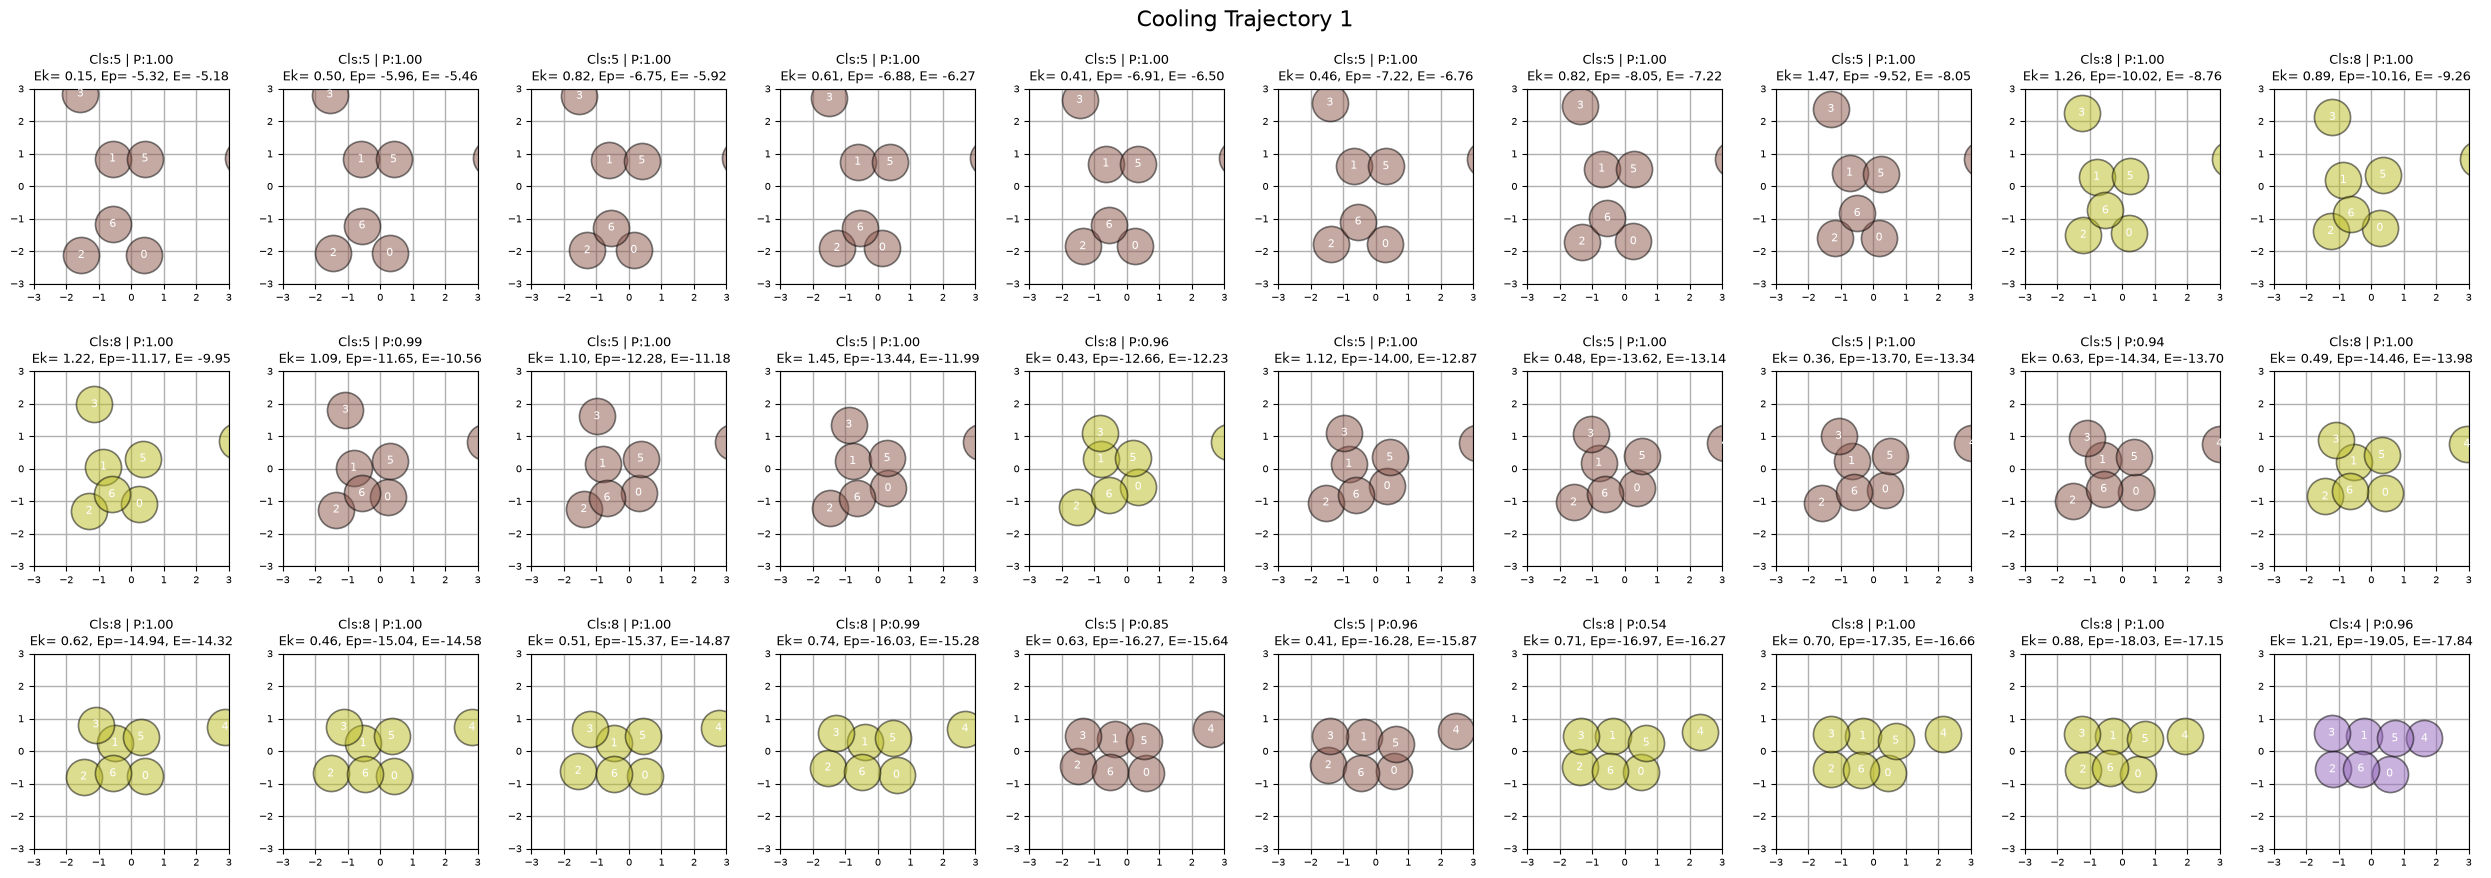

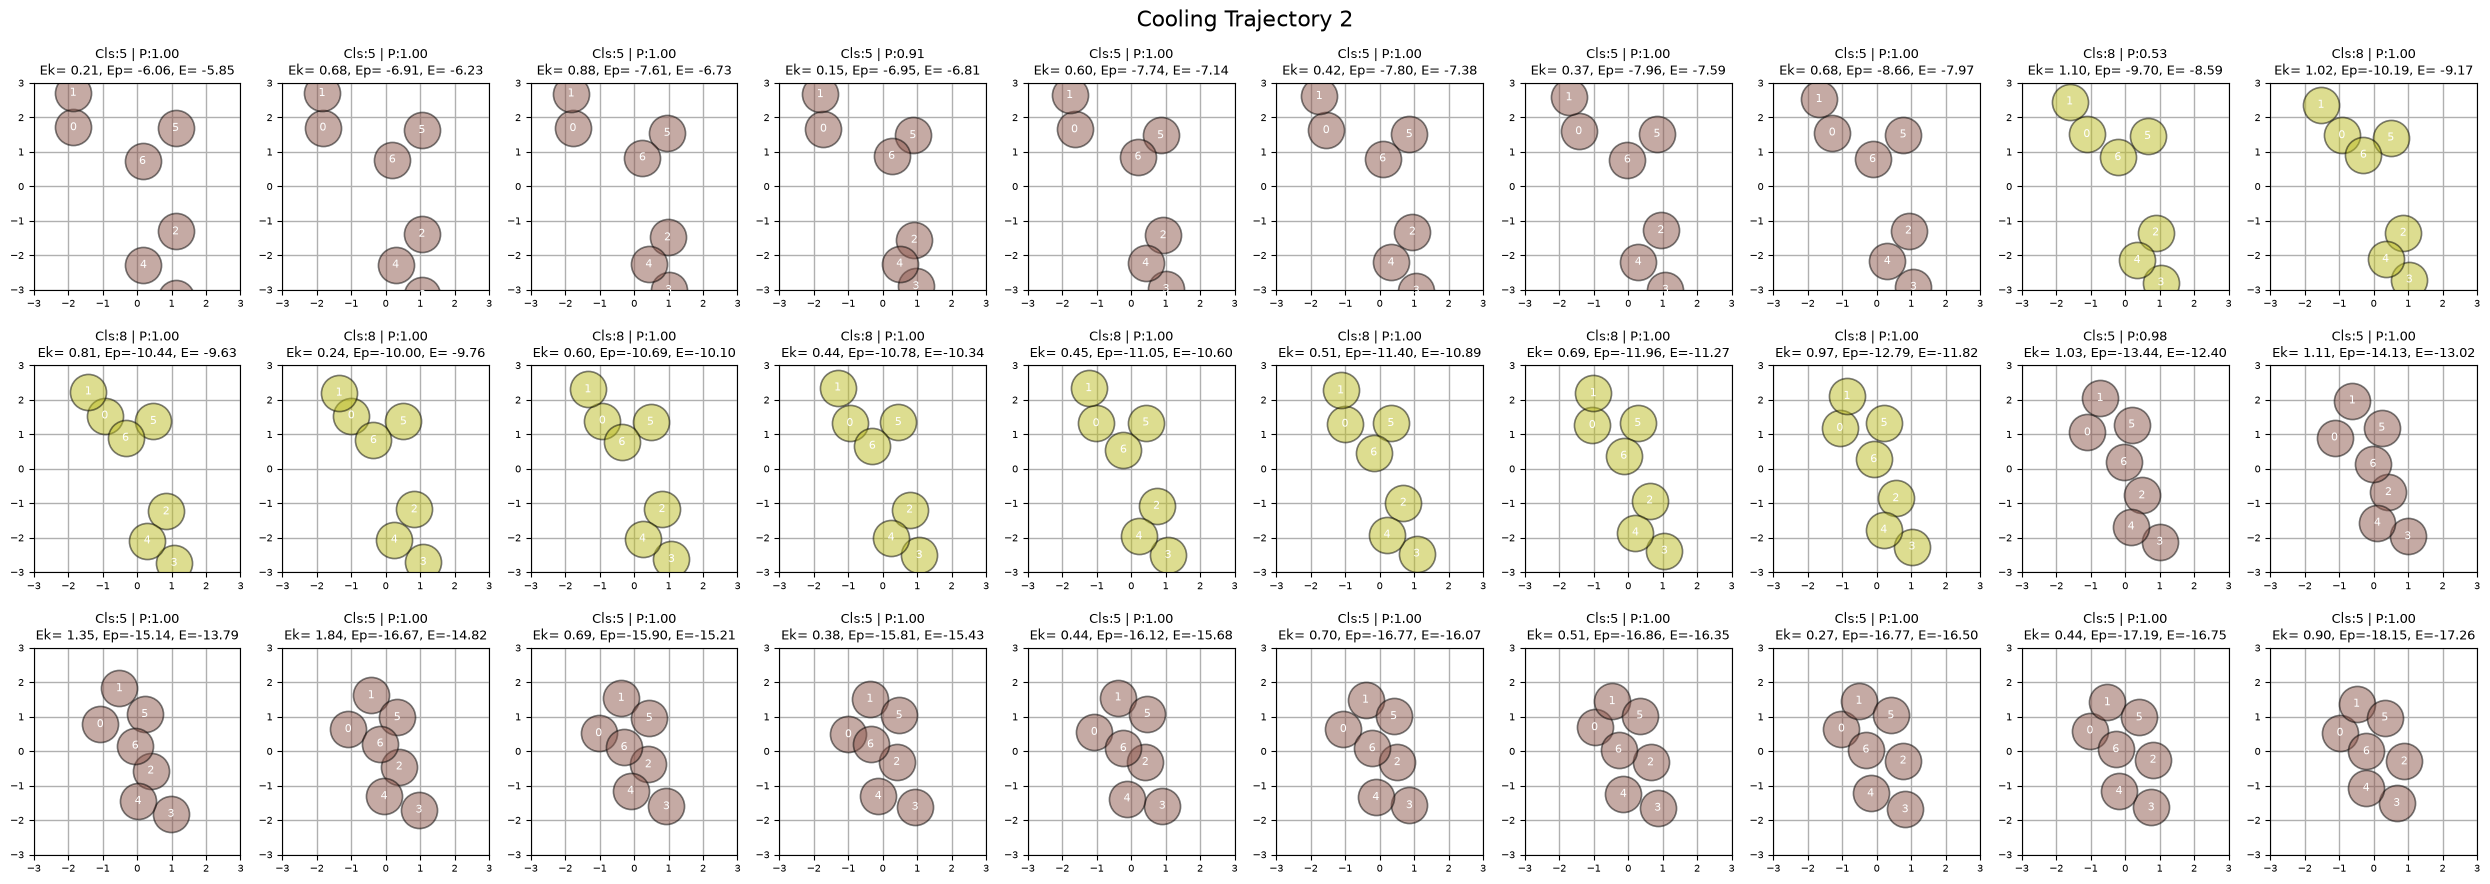

In [23]:
def cooling_trajectory(seed):
    np.random.seed(seed)
    
    calc = ModifiedMorse()
    
    pos = np.random.randint(-3, 4, (7, 2)).astype(float)
    while len(np.unique(pos, axis=0)) < 7:
        pos = np.random.randint(-3, 4, (7, 2)).astype(float)
        
    cluster = AtomicCluster(calc, pos=pos)
    
    snapshots = []
    dt = 0.01
    
    forces = calc.forces(cluster.pos)
    
    for step in range(1, 1001):
        cluster.velocities += 0.5 * dt * forces
        cluster.pos += dt * cluster.velocities
        forces = calc.forces(cluster.pos)
        cluster.velocities += 0.5 * dt * forces
        
        if step % 20 == 0:
            cluster.velocities *= 0.8
            
            desc_np = np.array(cluster.descriptor)
            desc_tensor = torch.tensor(desc_np, dtype=torch.float32).unsqueeze(0).to(device)
            with torch.no_grad():
                logits = model(desc_tensor)
                probs = torch.softmax(logits, dim=1)
                pred_class = torch.argmax(probs, dim=1).item()
                max_prob = probs[0, pred_class].item()
                
            snapshots.append({
                'pos': cluster.pos.copy(),
                'class': pred_class,
                'prob': max_prob,
                'ek': cluster.kinetic_energy,
                'ep': cluster.potential_energy
            })
            
    return snapshots

def plot_trajectory(snapshots, title):
    fig, axes = plt.subplots(3, 10, figsize=(25, 9))
    axes = axes.flatten()
    
    for i, snap in enumerate(snapshots[:30]):
        ax = axes[i]
        c = snap['pos']
        cls = snap['class']
        prob = snap['prob']
        ek = snap['ek']
        ep = snap['ep']
        etot = ek + ep
        
        c_centered = c - c.mean(axis=0)
        
        ax.plot(c_centered[:, 0], c_centered[:, 1], 'o', markersize=26, color=plt.cm.tab10(cls), alpha=0.5, markeredgecolor='k', markeredgewidth=1.2)
        
        for j in range(7):
            ax.text(c_centered[j, 0], c_centered[j, 1], str(j), ha='center', va='center', color='white', fontsize=8)
            
        ax.set_title(f"Cls:{cls} | P:{prob:.2f}\nEk={ek:5.2f}, Ep={ep:6.2f}, E={etot:6.2f}", fontsize=9)
        
        ax.set_xlim(-3, 3)
        ax.set_ylim(-3, 3)
        ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
        ax.set_yticks([-3, -2, -1, 0, 1, 2, 3])
        
        ax.tick_params(axis='both', which='major', labelsize=7)
        
        ax.set_aspect('equal')
        ax.grid(True, linestyle='-', linewidth=1)
        
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

traj1 = cooling_trajectory(3)
plot_trajectory(traj1, "Cooling Trajectory 1")

traj2 = cooling_trajectory(2)
plot_trajectory(traj2, "Cooling Trajectory 2")

### Discussion

* **Relaxed Structure Confidence:** Once the cluster has relaxed and shed its kinetic energy into a stable, compact structure, the class assignments are highly convincing. The predicted class stabilizes, and the probability output converges toward 1.0, indicating the network confidently identifies the structural basin.


* **Distorted Early Trajectories:** During the early, highly distorted phases where the atoms are violently snapping together from a loose grid, confident class assignments should absolutely not be expected. The network was trained strictly on low-energy, semi-relaxed heptamers; it has no mapping for high-energy scattering states.


* **Prediction Smoothness:** The network prediction does not evolve smoothly; instead, it jumps sporadically between different classes during the initial chaotic phase of the trajectory. It only locks into a consistent classification once the geometric basin begins to form.


* **Out-of-Distribution Structures:** Because the network features a linear output layer and must always categorize an input into one of the 10 known labels, it will assign an arbitrary label (often with surprisingly high softmax confidence) to any unrecognized state. We observe this in the early trajectory when loose, string-like structures are confidently misclassified as compact hexagons merely because they lie on the far side of a learned hyper-plane boundary. Thus, a high probability does not prove a structure belongs to a known class if its underlying geometry is out-of-distribution.